# Linear Regression: advanced training

This is the latest experiment. The earlier baseline and optimized notebooks remain as historical evidence. These cells load and verify the completed run. They do not repeat training.

Linear Regression because it is a simple, fast starting model for predicting numerical values. It helps us check how well a basic relationship between the inputs and energy usage can predict consumption.

## 1. Load Python tools and find the project
X is the table of inputs, y is the actual energy usage. The saved model contains its own preprocessing.

In [10]:
from pathlib import Path
import sys, json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image
start = Path.cwd()
ROOT = next(p for p in [start, *start.parents] if (p / "src" / "advanced_training.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.advanced_training import make_model, extended_scores
from src.regression_common import load_data

## 2. Load the saved run and its original data
There are 15 named inputs at the model boundary. Feature engineering happens inside the model. Its metadata records the exact data directory and settings.

In [2]:
KIND = 'linear'
OUTPUT_DIR = ROOT / 'linear regression' / "outputs_advanced"
metadata = json.loads((OUTPUT_DIR / "run_metadata.json").read_text())
settings = metadata["settings"]
X_train, X_test, y_train, y_test = load_data(metadata["input_directory"])
print("Training rows:", len(X_train), "Test rows:", len(X_test))

Training rows: 28511 Test rows: 5857


## 3. Explain the validation design
TimeSeriesSplit creates five expanding training windows. Every validation window occurs after its fitting data. We screen candidates on the last two windows, then compare finalists across all five. The previous optimized configuration is always evaluated as a finalist. These tuning scores are not an independent nested-CV estimate.

In [3]:
display(pd.read_csv(OUTPUT_DIR / "fold_boundaries.csv"))
trials = pd.read_csv(OUTPUT_DIR / "validation_trials.csv")
print("Screening trials:", (trials.phase == "screen").sum())
print("Full five-fold trials:", (trials.phase == "full_cv").sum())

,fold,fit_rows,validation_rows,fit_start,fit_end,validation_start,validation_end
0,1,4756,4751,2018-01-08 00:15:00,2018-02-26 13:00:00,2018-02-26 13:15:00,2018-04-17 00:45:00
1,2,9507,4751,2018-01-08 00:15:00,2018-04-17 00:45:00,2018-04-17 01:00:00,2018-06-05 12:30:00
2,3,14258,4751,2018-01-08 00:15:00,2018-06-05 12:30:00,2018-06-05 12:45:00,2018-07-25 00:15:00
3,4,19009,4751,2018-01-08 00:15:00,2018-07-25 00:15:00,2018-07-25 00:30:00,2018-09-12 12:00:00
4,5,23760,4751,2018-01-08 00:15:00,2018-09-12 12:00:00,2018-09-12 12:15:00,2018-10-31 23:45:00


Screening trials: 37
Full five-fold trials: 9


## 4. Understand the candidates
Linear Regression tests spline shapes, weekend schedules, removing load level and fit-only weighting. It still uses LinearRegression to learn coefficients. Random Forest tests tree settings, calendar features, weighting, and predicting either usage directly or its change since the previous interval. For change prediction, the saved model adds the previous usage back automatically. No SVR is trained.

In [4]:
display(trials.loc[trials.phase == "full_cv", ["RMSE_kWh", "MAE_kWh", "R2", "HighLoad_MAE", "RMSE_std", "specification"]].sort_values("RMSE_kWh"))

,RMSE_kWh,MAE_kWh,R2,HighLoad_MAE,RMSE_std,specification
44,9.912214,5.168254,0.901731,12.344421,1.079884,"{""knots"": 5, ""schedule"": ""weekend"", ""use_load""..."
41,9.938733,5.154315,0.901115,12.365347,1.136888,"{""knot_spacing"": ""uniform"", ""knots"": 5, ""sched..."
42,9.939803,5.237139,0.901114,12.370966,1.125176,"{""knots"": 8, ""schedule"": ""weekend"", ""use_load""..."
45,10.059655,5.240804,0.898301,12.635674,1.334137,"{""degree"": 2, ""knots"": 5, ""schedule"": ""weekend""}"
43,10.126946,5.289106,0.896572,12.747391,1.500286,"{""knots"": 5, ""schedule"": ""weekend"", ""use_load""..."
38,10.242456,5.333125,0.893451,12.978383,1.781579,"{""half_life_days"": 120, ""knots"": 5, ""schedule""..."
40,10.302961,5.434977,0.892061,13.023642,1.834678,"{""knots"": 8, ""schedule"": ""weekend"", ""use_load""..."
37,10.307470,5.425729,0.892647,12.796621,1.617469,"{""previous"": {""basis"": ""spline"", ""feature_mode..."
39,10.417376,5.421153,0.888817,13.286062,2.089670,"{""half_life_days"": 60, ""knots"": 5, ""schedule"":..."


## 5. Inspect the chosen configuration
The lowest average five-fold RMSE chooses the configuration. MAE and high-load MAE show trade-offs, but the test set does not select the winner. An untrained estimator is only a recipe; .fit(X, y) learns its parameters.

| Setting | Your value | Very simple meaning |
|---|---|---|
| `knots` | **5** | Use five reference points to create smooth curve-based features. |
| `degree` | **3** | Use cubic, or smoothly curved, spline features. |
| `knot_spacing` | **quantile** | Position those reference points according to the distribution of the training values. |
| `schedule` | **weekend** | Create features that allow weekday and weekend patterns to differ. |
| `use_load` | **False** | Do not use the load-category feature. |

In [5]:
print(json.dumps(settings["selected_specification"], indent=2))
print("Raw inputs:", settings["raw_input_features"], "Engineered inputs:", settings["transformed_features"])
untrained = make_model(KIND, settings["selected_specification"])
print(untrained)

{
  "knots": 5,
  "schedule": "weekend",
  "use_load": false
}
Raw inputs: 15 Engineered inputs: 651
AdvancedEnergyRegressor(estimator=Pipeline(steps=[('features',
                                                   ScheduleFeatures(mode='time96',
                                                                    schedule='weekend',
                                                                    use_load=False)),
                                                  ('basis',
                                                   ColumnTransformer(remainder='passthrough',
                                                                     transformers=[('smooth',
                                                                                    SplineTransformer(extrapolation='linear',
                                                                                                      include_bias=False,
                                                                                   

## 6. Inspect the final scores
The selected model is refitted on all 28,511 January-October training rows. MAE and RMSE are measured in kWh; lower is better. R2 is not accuracy percent. HighLoad_MAE includes only actual usage >= 50 kWh. cv_mean averages fold metrics, while cv_pooled computes metrics from all out-of-fold predictions together.

In [6]:
display(pd.read_csv(OUTPUT_DIR / "metrics.csv"))

,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Linear Regression,cv_mean,23755,5.168254,9.912214,0.901731,12.344421,NaN
1,Linear Regression,cv_pooled,23755,5.168254,9.970865,0.901501,12.399714,5698.0
2,Persistence,cv_pooled,23755,6.062173,13.512722,0.819094,15.604161,5698.0
3,Linear Regression,train,28511,4.984281,9.582444,0.919051,12.106227,7443.0
4,Linear Regression,test,5857,4.127699,7.880343,0.935930,9.671225,1491.0
5,Persistence,test,5857,5.155235,11.812549,0.856036,12.419591,1491.0


## 7. Verify the exported model
Loading this file and predicting again must reproduce the saved test results. This checks that preprocessing, target handling and nonnegative clipping were saved correctly.

In [7]:
model = joblib.load(OUTPUT_DIR / "model.joblib")
predictions = model.predict(X_test)
saved = pd.read_csv(OUTPUT_DIR / "test_predictions.csv", index_col=0)
np.testing.assert_allclose(predictions, saved.predicted_kWh, rtol=1e-10, atol=1e-8)
display(pd.DataFrame([extended_scores("Reloaded model", "test", y_test, predictions)]))
print("Saved model verified.")

,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Reloaded model,test,5857,4.127699,7.880343,0.93593,9.671225,1491


Saved model verified.


## 8. Read the error plots
Look at how predictions follow usage changes and where large errors remain. The model is a one-interval-ahead forecast with previous actual meter readings available, not a full day-ahead prediction.

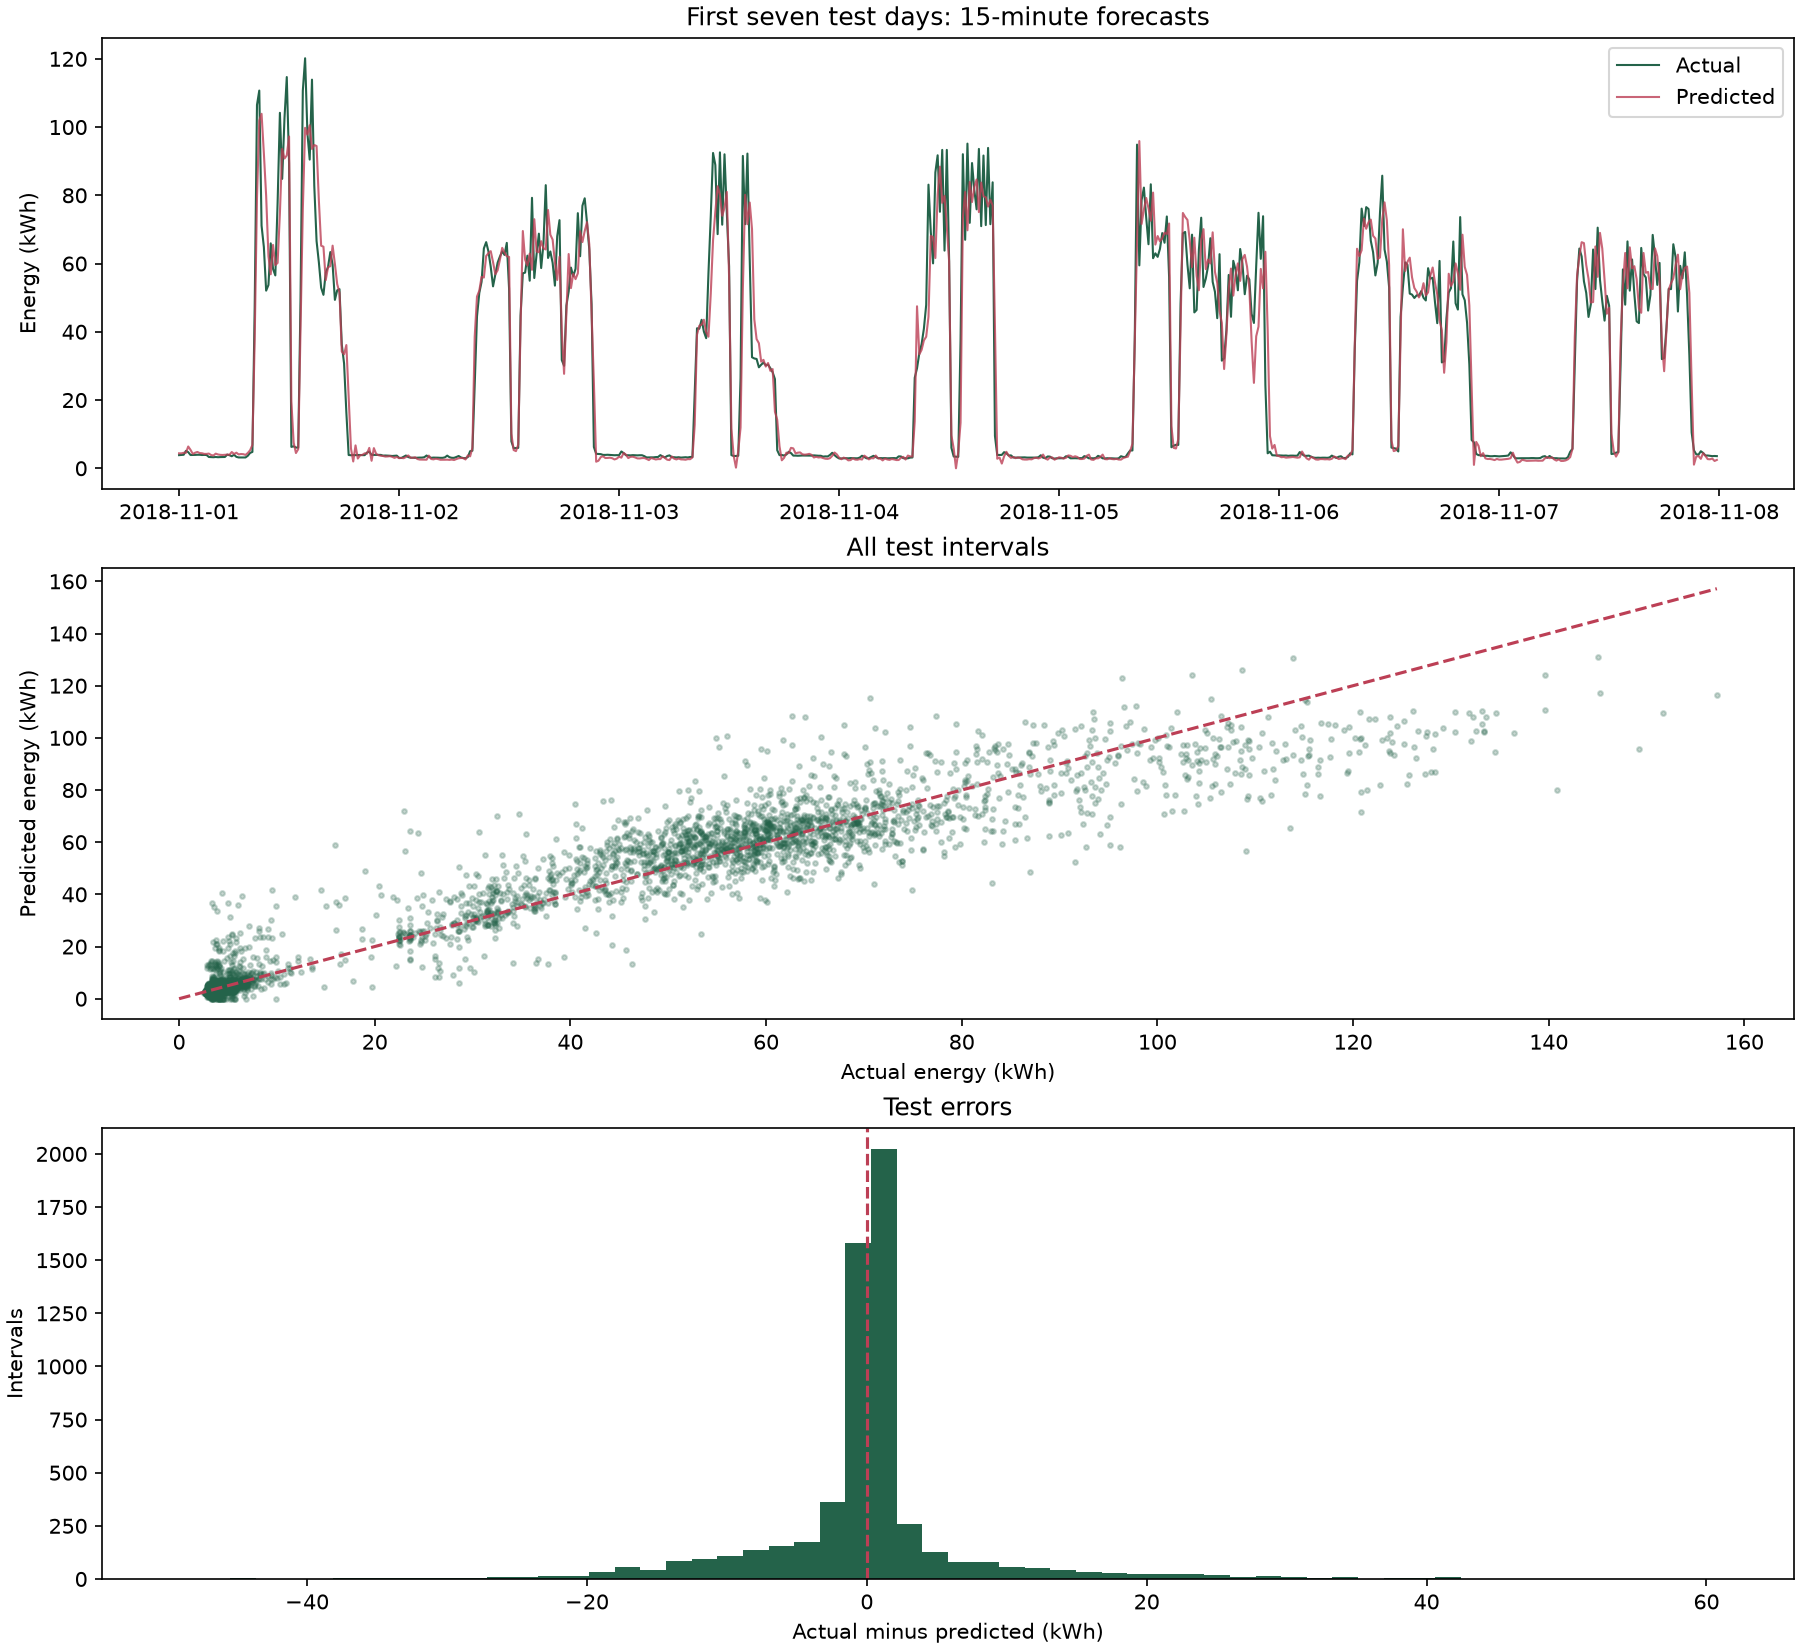

In [8]:
display(Image(filename=str(OUTPUT_DIR / "evaluation.png")))

## 9. Check assumptions and robustness
The interpolation sensitivity excludes the known imputed test target and every row whose saved lag/rolling features could depend on it. It does not repair all upstream preprocessing assumptions. The no-load check uses the last CV fold and does not choose a new model.

In [9]:
display(pd.read_csv(OUTPUT_DIR / "interpolation_sensitivity.csv"))
display(pd.read_csv(OUTPUT_DIR / "load_level_ablation.csv"))
display(pd.read_csv(OUTPUT_DIR / "test_monthly_metrics.csv"))
for note in metadata["limitations"]:
    print("-", note)

,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Selected configuration,exclude_interpolation_influence,5759,4.107815,7.855084,0.936332,9.686847,1453


,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Selected settings without load_level,last_cv_fold,4751,4.587667,9.144102,0.911452,11.677827,1068


,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Linear Regression,2018-11,2880,4.924874,9.025600,0.930156,10.679916,901
1,Linear Regression,2018-12,2976,3.357352,6.586606,0.940558,8.130834,590
2,Linear Regression,2019-01,1,0.816742,0.816742,NaN,NaN,0


- Forecasts are one interval ahead (15 minutes), with previous actual readings available before each prediction. This is not a day-ahead test.
- The selected transformer ignores load_level. It remains in the 15-column input schema, but no upcoming operating-load category is required.
- The supplied preprocessing shifts midnight rows to the next day; the original interval timestamp convention remains an assumption.
- The supplied preprocessing interpolates the target at 2018-11-08 00:00 using a future reading. This affects that test target and later lag/rolling features. Test results describe those supplied artifacts, not a fully causal evaluation of raw measurements.
- Upstream feature selection used the entire supplied training period, including September/October. Validation is provisional conditional on that fixed feature set; strict validation needs feature selection refitted on the earlier fitting period.
- The preprocessing notebook already inspected the test persistence score and

## 10. Reproduce only when needed
The experiment is already trained. The command below reruns the search and replaces only this model's outputs_advanced folder.

```bash
python src/advanced_training.py --model linear --train
```

Use `python src/show_model_results.py` for the terminal summary without retraining. Read `../reports/ADVANCED_TRAINING_REPORT.md` for the comparison and remaining limitations.